# Feature Engineering

---

1. Import packages
2. Load data
3. Feature engineering

---

## 1. Import packages

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score


---
## 2. Load data

In [43]:
df = pd.read_csv(r"C:/Users/KIRONJI/Desktop/BCG Data science simulation/data/clean/clean_data_after_eda.csv")
df["date_activ"] = pd.to_datetime(df["date_activ"], format='%Y-%m-%d')
df["date_end"] = pd.to_datetime(df["date_end"], format='%Y-%m-%d')
df["date_modif_prod"] = pd.to_datetime(df["date_modif_prod"], format='%Y-%m-%d')
df["date_renewal"] = pd.to_datetime(df["date_renewal"], format='%Y-%m-%d')

In [44]:
df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,var_6m_price_off_peak_var,var_6m_price_peak_var,var_6m_price_mid_peak_var,var_6m_price_off_peak_fix,var_6m_price_peak_fix,var_6m_price_mid_peak_fix,var_6m_price_off_peak,var_6m_price_peak,var_6m_price_mid_peak,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,0.000131,4.100838e-05,0.000908,2.086294,99.530517,44.235794,2.086425,9.953056e+01,44.236702,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,0.000003,1.217891e-03,0.000000,0.009482,0.000000,0.000000,0.009485,1.217891e-03,0.000000,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,0.000004,9.450150e-08,0.000000,0.000000,0.000000,0.000000,0.000004,9.450150e-08,0.000000,0


---

## 3. Feature engineering

### Difference between off-peak prices in December and preceding January

Below is the code created by your colleague to calculate the feature described above. Use this code to re-create this feature and then think about ways to build on this feature to create features with a higher predictive power.

In [45]:
price_df = pd.read_csv(r"C:/Users/KIRONJI/Desktop/BCG Data science simulation/data/raw/price_data.csv")
price_df["price_date"] = pd.to_datetime(price_df["price_date"], format='%Y-%m-%d')
price_df.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0


In [46]:
# Group off-peak prices by companies and month
monthly_price_by_id = price_df.groupby(['id', 'price_date']).agg({'price_off_peak_var': 'mean', 'price_off_peak_fix': 'mean'}).reset_index()

# Get january and december prices
jan_prices = monthly_price_by_id.groupby('id').first().reset_index()
dec_prices = monthly_price_by_id.groupby('id').last().reset_index()

# Calculate the difference
diff = pd.merge(dec_prices.rename(columns={'price_off_peak_var': 'dec_1', 'price_off_peak_fix': 'dec_2'}), jan_prices.drop(columns='price_date'), on='id')
diff['offpeak_diff_dec_january_energy'] = diff['dec_1'] - diff['price_off_peak_var']
diff['offpeak_diff_dec_january_power'] = diff['dec_2'] - diff['price_off_peak_fix']
diff = diff[['id', 'offpeak_diff_dec_january_energy','offpeak_diff_dec_january_power']]
diff.head()

,id,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power
0,0002203ffbb812588b632b9e628cc38d,-0.006192,0.162916
1,0004351ebdd665e6ee664792efc4fd13,-0.004104,0.177779
2,0010bcc39e42b3c2131ed2ce55246e3c,0.050443,1.500000
3,0010ee3855fdea87602a5b7aba8e42de,-0.010018,0.162916
4,00114d74e963e47177db89bc70108537,-0.003994,-0.000001


Now it is time to get creative and to conduct some of your own feature engineering! Have fun with it, explore different ideas and try to create as many as you can!

- To do away with peak and mid peak prices as we are investigating whether a difference between the off peak prices in january and december the preceeding year is a significant featurein predicting churn

In [47]:
price_df=pd.merge(price_df,diff, how='left', on='id')

In [48]:
price_df.columns
price_df.head()

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0,-0.005508,0.177779
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0,-0.005508,0.177779
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0,-0.005508,0.177779
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,0.0,0.0,44.266931,0.0,0.0,-0.005508,0.177779
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,0.0,0.0,44.266931,0.0,0.0,-0.005508,0.177779


In [49]:
price_df=price_df.drop(columns=['price_peak_var','price_peak_fix','price_mid_peak_fix','price_mid_peak_var'])


In [50]:
price_df.head()

,id,price_date,price_off_peak_var,price_off_peak_fix,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,44.266931,-0.005508,0.177779
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,44.266931,-0.005508,0.177779
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,44.266931,-0.005508,0.177779
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,44.266931,-0.005508,0.177779
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,44.266931,-0.005508,0.177779


- Engineer a customer level table with te id , prices the difference and a churn label
- added the average off peak price to assess mean and variation in price for each customer
- added pct change off peak var; shows the relative price increase/decrease

In [51]:
price_df['month'] = price_df['price_date'].dt.month
jan_dec = price_df[
    price_df['month'].isin([1, 12])
].copy()

In [52]:
jan_dec.groupby('month')['id'].nunique()

month
1     16070
12    16094
Name: id, dtype: int64

In [53]:
jan_price = (
    price_df.loc[price_df["month"] == 1]
    .groupby("id")["price_off_peak_var"]
    .mean()
)

dec_price = (
    price_df.loc[price_df["month"] == 12]
    .groupby("id")["price_off_peak_var"]
    .mean()
)

average_jan_dec = (jan_price + dec_price) / 2

price_df["average_offpeak_var"] = price_df["id"].map(average_jan_dec)

In [54]:
jan_dec = (
    price_df.loc[price_df["month"].isin([1, 12])]
    .pivot_table(
        index="id",
        columns="month",
        values="price_off_peak_var",
        aggfunc="mean"
    )
    .reindex(columns=[1, 12])
)

pct_change_by_id = (
    (jan_dec[12] - jan_dec[1]) / jan_dec[1] * 100
)

price_df["pct_change_offpeak_var"] = price_df["id"].map(pct_change_by_id)
price_df["pct_change_offpeak_var"] = price_df["pct_change_offpeak_var"].replace([np.inf, -np.inf], np.nan)

In [55]:
price_df.head()

,id,price_date,price_off_peak_var,price_off_peak_fix,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power,month,average_offpeak_var,pct_change_offpeak_var
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,44.266931,-0.005508,0.177779,1,0.148613,-3.638838
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,44.266931,-0.005508,0.177779,2,0.148613,-3.638838
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,44.266931,-0.005508,0.177779,3,0.148613,-3.638838
3,038af19179925da21a25619c5a24b745,2015-04-01,0.149626,44.266931,-0.005508,0.177779,4,0.148613,-3.638838
4,038af19179925da21a25619c5a24b745,2015-05-01,0.149626,44.266931,-0.005508,0.177779,5,0.148613,-3.638838


In [56]:
client_df=pd.merge(df, price_df, how='left', on='id')

# Enginereed consumption behavior and customer characteristic features:
- monthly average consumption
- consumptio ratio;assesses the recent month's consumption relative to the monthly average
- contract length; will help investigate what contract length churners subscribe to
- has_gas; a label to distinguish churners based on their utility needs


*studying consumption behavior is key because:lower consumption implies change in business activity that may lead to less need for powerco*
*High consumers are more sensitive to price changes as they have more total expenditure*

*Customer tenure tells us who the churners are- newer or older clients*

In [57]:
client_df['monthly_avg_cons']=client_df['cons_12m']/12
safe_den=client_df['monthly_avg_cons'].replace(0, np.nan)
client_df['cons_ratio']=client_df['cons_last_month']/safe_den
print(client_df["cons_ratio"].describe().round(2))
print("inf values:", np.isinf(client_df["cons_ratio"]).sum())
client_df.head()

count    173745.00
mean          0.93
std           1.03
min           0.00
25%           0.00
50%           0.87
75%           1.35
max          15.32
Name: cons_ratio, dtype: float64
inf values: 0


,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,price_date,price_off_peak_var,price_off_peak_fix,offpeak_diff_dec_january_energy,offpeak_diff_dec_january_power,month,average_offpeak_var,pct_change_offpeak_var,monthly_avg_cons,cons_ratio
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,2015-01-01,0.125976,40.565969,0.020057,3.700961,1,0.136005,15.921287,0.0,NaN
1,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,2015-02-01,0.125976,40.565969,0.020057,3.700961,2,0.136005,15.921287,0.0,NaN
2,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,2015-03-01,0.125976,40.565973,0.020057,3.700961,3,0.136005,15.921287,0.0,NaN
3,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,2015-04-01,0.125976,40.565973,0.020057,3.700961,4,0.136005,15.921287,0.0,NaN
4,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,2015-05-01,0.125976,40.565973,0.020057,3.700961,5,0.136005,15.921287,0.0,NaN


In [58]:
client_df['contract_length']=client_df['date_end']-client_df['date_activ']
client_df['contract length']=client_df['contract_length'].dt.days /365

In [59]:
client_df["has_gas"] = client_df["has_gas"].map({"t": 1, "f": 0})
client_df["nb_prod_act_capped"] = client_df["nb_prod_act"].clip(upper=4)#there is a customer subscribed to 32 products 

In [60]:
churn_rate = client_df.groupby('id')['churn'].max().mean()
churn_rate

np.float64(0.09715185540188963)

- The min_count=97 because churn is about 9.7%, so a 100-client category has only about 10 churners. Below that, its churn rate is mostly luck ie;A category with 3 clients and 0 churners would look like “this channel never churns” which is noise
- I resorted to one hot encoding for channel_sales_grp and origini_up_grp as they aren't orders, summing up each group shows how big the group is and whether it's trustworthy to use

In [61]:
def group_rare(s, min_count=100, label="other"):
    counts = s.value_counts()
    keep = counts[counts >= min_count].index
    return s.where(s.isin(keep), label)

client_df["channel_sales_grp"] = group_rare(client_df["channel_sales"])
client_df["origin_up_grp"] = group_rare(client_df["origin_up"])

# One-hot encode (no order exists between channels, so label-encoding 0,1,2...
# would invent a fake ranking)
client_df = pd.get_dummies(client_df, columns=["channel_sales_grp", "origin_up_grp"], dtype=int)

# Check each remaining category is large enough to trust
print(client_df.filter(like="channel_sales_grp").sum())
print(client_df.filter(like="origin_up_grp").sum())

channel_sales_grp_MISSING                             44684
channel_sales_grp_ewpakwlliwisiwduibdlfmalxowmwpci    10712
channel_sales_grp_foosdfpfkusacimwkcsosbicdxkicaua    80971
channel_sales_grp_lmkebamcaaclubfxadlmueccxoimlema    22105
channel_sales_grp_other                                  60
channel_sales_grp_sddiedcslfslkckwlfkdpoeeailfpeds      131
channel_sales_grp_usilxuppasemubllopkaafesmlibmsdf    16486
dtype: int64
origin_up_grp_MISSING                               767
origin_up_grp_kamkkxfxxuwbdslkwifmmcsiusiuosws    51503
origin_up_grp_ldkssxwpmemidmecebumciepifcamkci    37757
origin_up_grp_lxidpiddsbxsbosboudacockeimpuepw    85086
origin_up_grp_other                                  36
dtype: int64


In [62]:
client_df.head()

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,channel_sales_grp_foosdfpfkusacimwkcsosbicdxkicaua,channel_sales_grp_lmkebamcaaclubfxadlmueccxoimlema,channel_sales_grp_other,channel_sales_grp_sddiedcslfslkckwlfkdpoeeailfpeds,channel_sales_grp_usilxuppasemubllopkaafesmlibmsdf,origin_up_grp_MISSING,origin_up_grp_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_grp_ldkssxwpmemidmecebumciepifcamkci,origin_up_grp_lxidpiddsbxsbosboudacockeimpuepw,origin_up_grp_other
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,1,0,0,0,0,0,0,0,1,0
1,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,1,0,0,0,0,0,0,0,1,0
2,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,1,0,0,0,0,0,0,0,1,0
3,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,1,0,0,0,0,0,0,0,1,0
4,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.0,...,1,0,0,0,0,0,0,0,1,0


---
## 4. Repair

**upon further investigation:**  `client_df = pd.merge(df, price_df, how='left', on='id')` joins a *monthly* price table onto a *client* table, so every client is repeated about 12 times. That:
- inflates every count (the one-hot sums are ~12x too big,
- would put the same client in both train and test splits  later.

*I build a `master` table with exactly one row per `id`, using client-level price features only.*

In [63]:
print("client_df rows:", len(client_df), "| unique clients:", client_df["id"].nunique(), "| rows in df:", len(df))
print(client_df.groupby("id").size().describe().round(1))

client_df rows: 175149 | unique clients: 14606 | rows in df: 14606
count    14606.0
mean        12.0
std          0.1
min          7.0
25%         12.0
50%         12.0
75%         12.0
max         12.0
dtype: float64


In [64]:
master = (client_df
          .drop(columns=["price_date", "price_off_peak_var", "price_off_peak_fix", "month"])
          .drop(columns=client_df.filter(regex="_grp_").columns)      
          .drop_duplicates(subset="id")
          .reset_index(drop=True))
# built Jan/Dec price differences, built explicitly from the month (safer than groupby().first()/last(),
# which silently picks the wrong month when a client is missing January or December)
def jan_dec(col):
    return (price_df[price_df["month"].isin([1, 12])]
            .pivot_table(index="id", columns="month", values=col, aggfunc="mean")
            .reindex(columns=[1, 12]))

var_p, fix_p = jan_dec("price_off_peak_var"), jan_dec("price_off_peak_fix")
price_feats = pd.DataFrame({
    "offpeak_diff_energy":     var_p[12] - var_p[1],
    "offpeak_diff_power":      fix_p[12] - fix_p[1],
    "offpeak_abs_diff_energy": (var_p[12] - var_p[1]).abs(),   # size of the move, ignoring direction
}).reset_index()
master = master.merge(price_feats, on="id", how="left")

#  re-did the rare-category grouping + one-hot on the correct one-row-per-client table
master["channel_sales_grp"] = group_rare(master["channel_sales"])
master["origin_up_grp"] = group_rare(master["origin_up"])
master = pd.get_dummies(master, columns=["channel_sales_grp", "origin_up_grp"], dtype=int)

**Validate the master table** (rows, uniqueness, missing values, category sizes)

In [65]:
assert len(master) == len(df) and master["id"].is_unique
print("master shape:", master.shape, "| churn rate:", round(master["churn"].mean(), 4))
price_cols = ["offpeak_diff_energy", "offpeak_diff_power", "offpeak_abs_diff_energy",
              "pct_change_offpeak_var", "average_offpeak_var"]
print("\nMissing values in price features:\n", master[price_cols].isna().sum())
print("inf values:", np.isinf(master[price_cols]).sum().sum())

print("\nCategory sizes:")
print(master.filter(like="channel_sales_grp").sum())
print(master.filter(like="origin_up_grp").sum())

master shape: (14606, 66) | churn rate: 0.0972

Missing values in price features:
 offpeak_diff_energy        22
offpeak_diff_power         22
offpeak_abs_diff_energy    22
pct_change_offpeak_var     47
average_offpeak_var        22
dtype: int64
inf values: 0

Category sizes:
channel_sales_grp_MISSING                             3725
channel_sales_grp_ewpakwlliwisiwduibdlfmalxowmwpci     893
channel_sales_grp_foosdfpfkusacimwkcsosbicdxkicaua    6754
channel_sales_grp_lmkebamcaaclubfxadlmueccxoimlema    1843
channel_sales_grp_other                                 16
channel_sales_grp_usilxuppasemubllopkaafesmlibmsdf    1375
dtype: int64
origin_up_grp_kamkkxfxxuwbdslkwifmmcsiusiuosws    4294
origin_up_grp_ldkssxwpmemidmecebumciepifcamkci    3148
origin_up_grp_lxidpiddsbxsbosboudacockeimpuepw    7097
origin_up_grp_other                                 67
dtype: int64


---
## 5. Review variables and identify redundancy
### Framework
Redundant variables repeat the same information. They add noise and split the importance of one signal across several columns
1. **Inventory** - list the commercial variables and check zeros, missing values and skew.
2. **Exact duplicates** - check whether a column is a function of another-a sum or identical
3. **Near duplicates** - Spearman correlation between pairs.
4. for each flagged pair, I keep the one with the higher single-variable AUC. If the AUCs are within about 0.005 I keep the simpler column.


In [66]:
y = master["churn"]

def auc_of(s):
    ok = s.notna()
    a = roc_auc_score(y[ok], s[ok])
    return max(a, 1 - a)

### 5.1 Inventory

In [67]:
pricing   = ["forecast_price_energy_off_peak", "forecast_price_energy_peak", "forecast_price_pow_off_peak",
             "forecast_discount_energy", "forecast_meter_rent_12m"]
margins   = ["margin_gross_pow_ele", "margin_net_pow_ele", "net_margin"]
new_price = ["offpeak_diff_energy", "offpeak_diff_power", "offpeak_abs_diff_energy",
             "pct_change_offpeak_var", "average_offpeak_var"]
all_var   = [c for c in master.columns if c.startswith("var_")]          # the 18 var_year_* / var_6m_* columns
var_cols  = [c for c in all_var if "off_peak" in c]                      # in scope: off-peak only
peak_cols = [c for c in all_var if "off_peak" not in c]                  # peak / mid-peak: set asidide
other     = ["pow_max", "nb_prod_act", "has_gas", "num_years_antig"]

commercial = pricing + margins + new_price + var_cols + other

inventory = pd.DataFrame({
    "pct_zero": (master[commercial] == 0).mean(),
    "pct_missing": master[commercial].isna().mean(),
    "skew": master[commercial].skew(),
    "auc_vs_churn": [auc_of(master[c]) for c in commercial],
}).round(3)
display(inventory)

,pct_zero,pct_missing,skew,auc_vs_churn
forecast_price_energy_off_peak,0.002,0.000,-0.120,0.532
forecast_price_energy_peak,0.481,0.000,-0.014,0.533
forecast_price_pow_off_peak,0.006,0.000,-4.999,0.522
forecast_discount_energy,0.965,0.000,5.155,0.506
forecast_meter_rent_12m,0.050,0.000,1.505,0.540
margin_gross_pow_ele,0.011,0.000,4.473,0.600
margin_net_pow_ele,0.011,0.000,4.473,0.600
net_margin,0.013,0.000,36.570,0.519
offpeak_diff_energy,0.007,0.002,3.379,0.532
offpeak_diff_power,0.100,0.002,-9.317,0.509


### 5.2 Exact duplicates and identities

In [68]:
# Are the 'total' price columns just var + fix?  (
for period in ["year", "6m"]:
    for band in ["off_peak", "peak", "mid_peak"]:
        total = master[f"var_{period}_price_{band}"]
        parts = master[f"var_{period}_price_{band}_var"] + master[f"var_{period}_price_{band}_fix"]
        print(f"var_{period}_price_{band:<9}: max |total - (var + fix)| = {(total - parts).abs().max():.6f}")

# Are gross and net margin the same column?
same = (master["margin_gross_pow_ele"] == master["margin_net_pow_ele"]).mean()
print(f"\nmargin_gross == margin_net in {same:.2%} of clients")

var_year_price_off_peak : max |total - (var + fix)| = 0.000000
var_year_price_peak     : max |total - (var + fix)| = 0.000000
var_year_price_mid_peak : max |total - (var + fix)| = 0.000000
var_6m_price_off_peak : max |total - (var + fix)| = 0.000000
var_6m_price_peak     : max |total - (var + fix)| = 0.000000
var_6m_price_mid_peak : max |total - (var + fix)| = 0.000000

margin_gross == margin_net in 99.99% of clients


### 5.3 Near duplicates

In [69]:
corr = master[commercial].corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))    
pairs = upper.stack().reset_index()
pairs.columns = ["var_a", "var_b", "spearman"]
pairs = pairs[pairs["spearman"] >= 0.85].sort_values("spearman", ascending=False)

pairs["auc_a"] = pairs["var_a"].map(lambda c: auc_of(master[c]))
pairs["auc_b"] = pairs["var_b"].map(lambda c: auc_of(master[c]))
pairs["status"] = np.where(pairs["spearman"] >= 0.90, "drop one", "watch")
display(pairs.round(3).reset_index(drop=True))

,var_a,var_b,spearman,auc_a,auc_b,status
0,margin_gross_pow_ele,margin_net_pow_ele,1.000,0.600,0.600,drop one
1,offpeak_diff_energy,pct_change_offpeak_var,0.987,0.532,0.535,drop one
2,var_year_price_off_peak_fix,var_year_price_off_peak,0.981,0.501,0.502,drop one
3,forecast_price_energy_off_peak,average_offpeak_var,0.959,0.532,0.529,drop one
4,offpeak_abs_diff_energy,var_year_price_off_peak_var,0.898,0.542,0.550,watch
5,nb_prod_act,has_gas,0.897,0.511,0.516,watch
6,var_6m_price_off_peak_fix,var_6m_price_off_peak,0.881,0.507,0.509,watch


### 5.4 Decision

In [70]:
redundant_drop = [
    "margin_gross_pow_ele",       # identical to margin_net_pow_ele in ~99.99% of clients
    "pct_change_offpeak_var",     # rho ~0.99 with offpeak_diff_energy; AUC gap is noise
    "average_offpeak_var",        # rho ~0.96 with forecast_price_energy_off_peak, no AUC advantage
    # off-peak 'total' columns are exactly var + fix, so they carry no new information
    "var_year_price_off_peak", "var_6m_price_off_peak",
]

# Scope decision: peak / mid-peak var_* columns are outside the off-peak hypothesis.
scope_drop = peak_cols

master_reduced = master.drop(columns=redundant_drop + scope_drop)
print("Dropped for redundancy:", len(redundant_drop), "| set aside for scope:", len(scope_drop))
print("columns before/after:", master.shape[1], "->", master_reduced.shape[1])

Dropped for redundancy: 5 | set aside for scope: 12
columns before/after: 66 -> 49


---
## 6. Explore interactions

### Framework
I investigated the interactions betwen feature pairs ie; the effect of variable A on churn *depends on* variable B. Testing every pair is wasteful and produces false positives, so:

1. *Came up with hypothesis and from each picked a relevant pair to test* 
2. *split each variable into low/mid/high and compare churn rates in a grid.*


In [71]:
pairs_to_test = [
    ("offpeak_abs_diff_energy", "cons_12m"),            # high consumers more price-sensitive?
    ("offpeak_abs_diff_energy", "num_years_antig"),     # newer clients react more to a price move?
    ("cons_ratio",              "offpeak_abs_diff_energy"),  # falling usage + price move?
    ("margin_net_pow_ele",      "num_years_antig"),     # the two strongest single signals together
    ("nb_prod_act_capped",      "offpeak_abs_diff_energy"),  # more products = less price-sensitive?
]

def bins(s):
    """Low/mid/high thirds; variables with <=4 distinct values keep their own values."""
    return s if s.nunique() <= 4 else pd.qcut(s, 3, labels=False, duplicates="drop")

def churn_grid(a, b, ax):
    g = pd.DataFrame({"A": bins(master_reduced[a]), "B": bins(master_reduced[b]), "churn": y})
    rate = g.pivot_table(index="A", columns="B", values="churn", aggfunc="mean")
    n = g.pivot_table(index="A", columns="B", values="churn", aggfunc="count").fillna(0).astype(int)
    labels = np.array([[f"{r:.1%}\n(n={c})" for r, c in zip(rr, cc)] for rr, cc in zip(rate.values, n.values)])
    sns.heatmap(rate, annot=labels, fmt="", cmap="Reds", vmin=0.04, vmax=0.18, cbar=False, ax=ax)
    ax.set_ylabel(a); ax.set_xlabel(b)

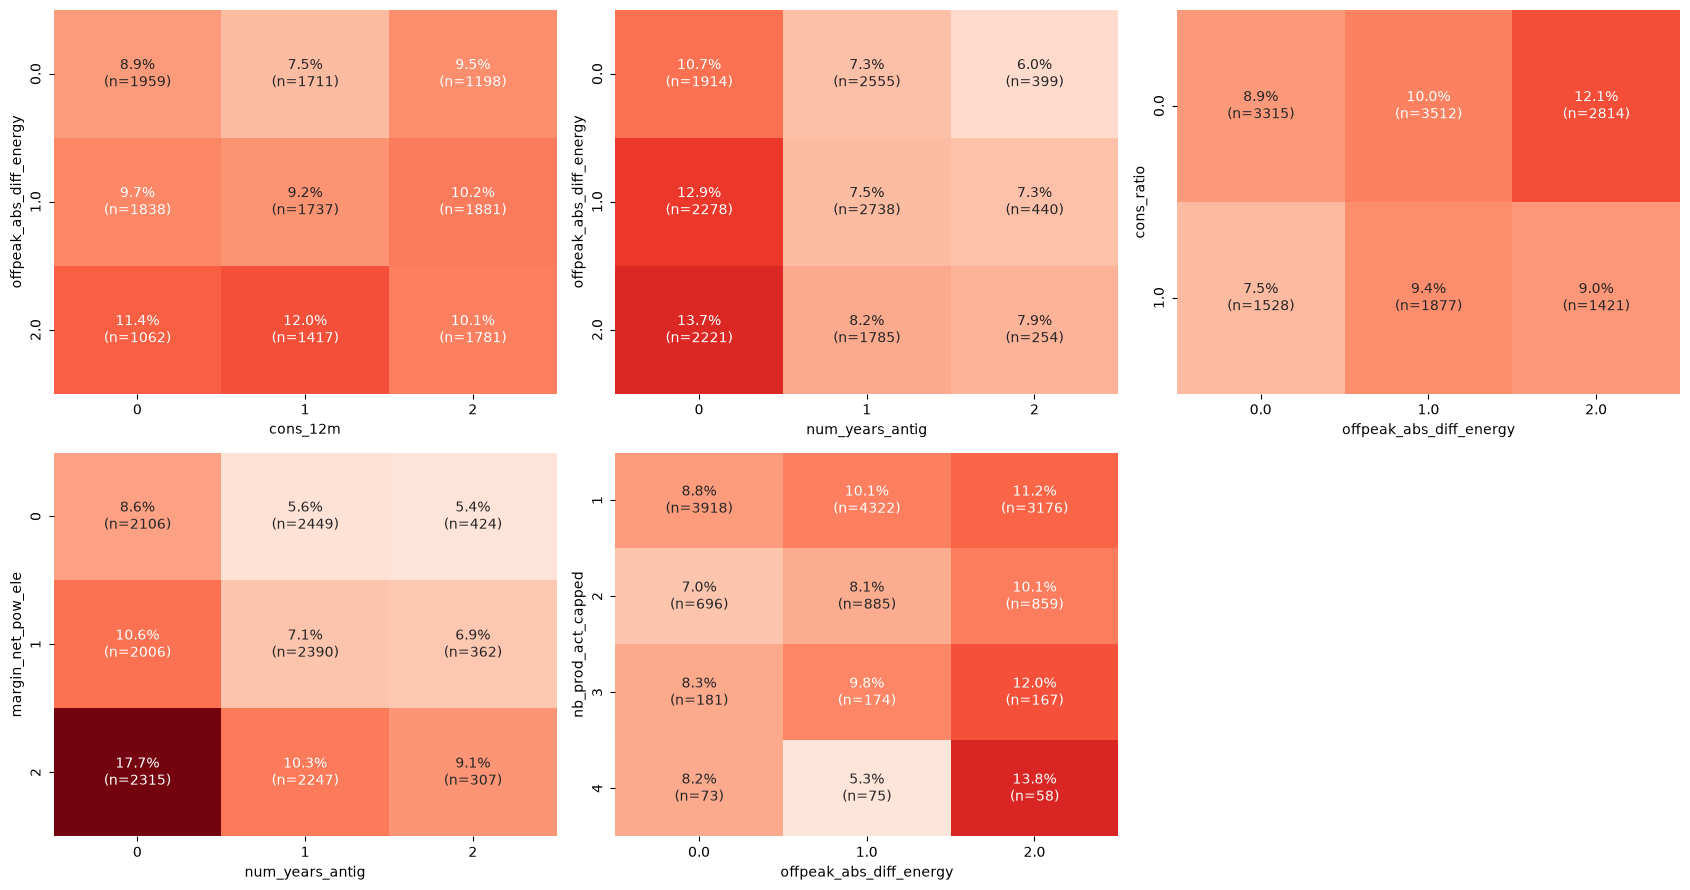

In [72]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (a, b) in zip(axes.ravel(), pairs_to_test):
    churn_grid(a, b, ax)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

- Price move size is a modest, consistent effect. Churn goes up with it nearly everywhere.
- Tenure and margin are the strongest drivers in these plots.
- Consumption level shows nothing.
- The patterns stack rather than change shape

*Churn rises with the size of the Dec–Jan off-peak price move across almost all groups, and is far higher for newer clients (10–14% vs 6–8%) and higher-margin clients (up to 17.7% when both apply). Consumption level shows no pattern. Effects mostly stack rather than change shape, so I’ll let the model combine them and add no interaction columns*

## Findings 

Use: **what I see (a number) -> what it suggests (hedged) -> what I do.**

| Step | Observation | Meaning | Action |
|---|---|---|---|
| Master repair |the previous df was merger of monthly price data and client data|the data is thus inflated ie same id and values repeated across several rows  |I dropped the monthly columns, re engineered some price features and correclty merged|
| Redundancy: identities |Total columns were a sum of var and fix , margin gross and net were 99.99% identical ,4 pairs were greatly correlated>0.9 |Flagged fetaures were redudndant and carried noise and the same signal across many columns |dropped one feature from each flagged pair based on the simplicity pf the column and auc advantage or it's lack thereoff |
| Interactions: grids |Churn rises with price movements in almost all categories,effects tend to stack up instead f change shape |tenure and margins carry the most signal with consumption holding none, it's holds that price movement is a factor accelerating churn |i will let the model combine them and won't add ineraction columns |

---
## 7. Feature-level analysis against churn

### Framework
The goal is to decide **which features earn a place in the model and how each should be treated**.

1. **Split first.** Do all the analysis on the training set only because If the test set influences which features we keep, the final test score is optimistic.
2. **Final redundancy sweep** across *every* candidate.
3. **Univariate profile** for each feature:
   - *AUC*: does a higher value rank churners higher ?
   - *Mutual information*: any kind of dependence, including U-shapes that AUC misses.
   - *Churn by quintile*: the actual shape, plus missing values.
4. **Categorical features**: churn rate per category and a chi-square test.

### 7.1 Split

In [73]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(master_reduced, test_size=0.2, stratify=master_reduced["churn"], random_state=42) # stratifying ensures all btih splits have the same 9.7% churn rate
y_train = train["churn"]

print("train:", train.shape, "| test:", test.shape)
print("churn rate  train:", round(y_train.mean(), 4), "| test:", round(test["churn"].mean(), 4))

def auc_train(s):
    """Single-variable AUC on the training set."""
    ok = s.notna()
    a = roc_auc_score(y_train[ok], s[ok])
    return max(a, 1 - a)

train: (11684, 49) | test: (2922, 49)
churn rate  train: 0.0971 | test: 0.0972


### 7.2 Final redundancy sweep
 Spearman >= 0.90 means "drop one" (keep the higher AUC; if the AUCs tie, keep the simpler column). 0.85-0.90 goes on the watch-list.

Not candidates: the id, the target, raw dates the `contract_length` timedelta, and the raw text categories plus their old one-hot columns.

In [74]:
not_features = (["id", "churn", "date_activ", "date_end", "date_modif_prod", "date_renewal",
                 "contract_length", "channel_sales", "origin_up"]
                + list(master_reduced.filter(like="_grp_").columns))
candidates = [c for c in train.columns if c not in not_features]

corr = train[candidates].corr(method="spearman").abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
sweep = upper.stack().reset_index()
sweep.columns = ["var_a", "var_b", "spearman"]
sweep = sweep[sweep["spearman"] >= 0.85].sort_values("spearman", ascending=False)
sweep["auc_a"] = sweep["var_a"].map(lambda c: auc_train(train[c]))
sweep["auc_b"] = sweep["var_b"].map(lambda c: auc_train(train[c]))
sweep["status"] = np.where(sweep["spearman"] >= 0.90, "drop one", "watch")
display(sweep.round(3).reset_index(drop=True))

,var_a,var_b,spearman,auc_a,auc_b,status
0,cons_12m,monthly_avg_cons,1.000,0.503,0.503,drop one
1,offpeak_diff_dec_january_power,offpeak_diff_power,1.000,0.509,0.509,drop one
2,offpeak_diff_dec_january_energy,offpeak_diff_energy,1.000,0.530,0.530,drop one
3,nb_prod_act,nb_prod_act_capped,1.000,0.508,0.508,drop one
4,forecast_cons_year,imp_cons,0.987,0.510,0.509,drop one
5,cons_gas_12m,has_gas,0.961,0.510,0.511,drop one
6,forecast_cons_12m,net_margin,0.949,0.510,0.524,drop one
7,num_years_antig,contract length,0.924,0.578,0.577,drop one
8,var_year_price_off_peak_var,offpeak_abs_diff_energy,0.898,0.552,0.541,watch
9,has_gas,nb_prod_act_capped,0.897,0.511,0.508,watch


In [75]:
drop_features = {
    "monthly_avg_cons":                "rank-identical to cons_12m (rho = 1.0); it was only needed as the denominator for cons_ratio",
    "nb_prod_act":                     "same ranking as nb_prod_act_capped; keep the capped version",
    "offpeak_diff_dec_january_energy": "first()/last() version; equals offpeak_diff_energy except for clients missing Jan or Dec",
    "offpeak_diff_dec_january_power":  "same as above for the power price",
    "imp_cons":                        "rho 0.99 with forecast_cons_year, AUC tie",
    "cons_gas_12m":                    "rho 0.96 with has_gas, AUC tie, has_gas is simpler",
    "forecast_cons_12m":               "rho 0.95 with net_margin, weaker AUC, and its scale/definition is unclear",
    "contract length":                 "rho 0.92 with num_years_antig, AUC tie",
}
features = [c for c in candidates if c not in drop_features]
print("candidates:", len(candidates), "| dropped:", len(drop_features), "| numeric features kept:", len(features))

candidates: 30 | dropped: 8 | numeric features kept: 22


**Watch-list (both kept):** `var_year_price_off_peak_var` vs `offpeak_abs_diff_energy` (0.898) and `has_gas` vs `nb_prod_act_capped` (0.897). They overlap but are not duplicates.

### 7.3 Univariate profile of every numeric feature
- **auc**: 0.5 = no signal. Only catches "higher value = more (or less) churn" in one direction.
- **mutual_info**: catches any shape. Compare it to the noise floor printed below it (what we get when churn labels are shuffled).
- **churn_low_bin / churn_high_bin / high_vs_low**: churn in the lowest vs highest fifth of the feature.
- **monotone**: does churn move in one direction across the fifths?

*A feature with a low AUC but a clearly-above-noise mutual information has a non-straight relationship with churn.*

In [76]:
from sklearn.feature_selection import mutual_info_classif

X_num = train[features]
mi = mutual_info_classif(X_num.fillna(X_num.median()), y_train, random_state=0)

# Noise floor: mutual information when the churn labels are randomly shuffled
mi_null = mutual_info_classif(X_num.fillna(X_num.median()), y_train.sample(frac=1, random_state=0).values, random_state=0)

rows = []
for c, m_info in zip(features, mi):
    s = train[c]
    groups = s if s.nunique() <= 2 else pd.qcut(s, 5, duplicates="drop")    # binary stays 0/1, the rest in fifths
    rate = y_train.groupby(groups, observed=True).mean()
    rows.append({"feature": c, "auc": auc_train(s), "mutual_info": m_info, "bins": len(rate),
                 "churn_low_bin": rate.iloc[0], "churn_high_bin": rate.iloc[-1],
                 "high_vs_low": rate.iloc[-1] / rate.iloc[0] if rate.iloc[0] > 0 else np.nan,
                 "monotone": rate.is_monotonic_increasing or rate.is_monotonic_decreasing,
                 "pct_missing": s.isna().mean()})

profile = pd.DataFrame(rows).sort_values("auc", ascending=False).round(3).reset_index(drop=True)
display(profile)
print("Mutual-information noise floor (shuffled labels): max =", mi_null.max().round(4))

,feature,auc,mutual_info,bins,churn_low_bin,churn_high_bin,high_vs_low,monotone,pct_missing
0,margin_net_pow_ele,0.604,0.015,5,0.069,0.158,2.294,True,0.000
1,num_years_antig,0.578,0.004,3,0.124,0.068,0.548,True,0.000
2,var_year_price_off_peak_var,0.552,0.005,5,0.073,0.121,1.650,False,0.000
3,var_6m_price_off_peak_var,0.544,0.005,5,0.078,0.108,1.382,False,0.000
4,offpeak_abs_diff_energy,0.541,0.008,5,0.079,0.116,1.478,True,0.001
5,forecast_meter_rent_12m,0.538,0.009,5,0.099,0.128,1.294,False,0.000
6,forecast_price_energy_peak,0.535,0.000,3,0.085,0.114,1.338,False,0.000
7,pow_max,0.535,0.002,5,0.090,0.112,1.244,False,0.000
8,forecast_price_energy_off_peak,0.533,0.005,5,0.108,0.087,0.810,False,0.000
9,offpeak_diff_energy,0.530,0.003,5,0.108,0.088,0.808,False,0.001


Mutual-information noise floor (shuffled labels): max = 0.0052


- `cons_12m` , `cons_ratio` , `cons_last_month` and `margin_net_pow_ele` have the highest m_infos- they are more associated to churn

### 7.4 Shapes: churn by bin of the feature

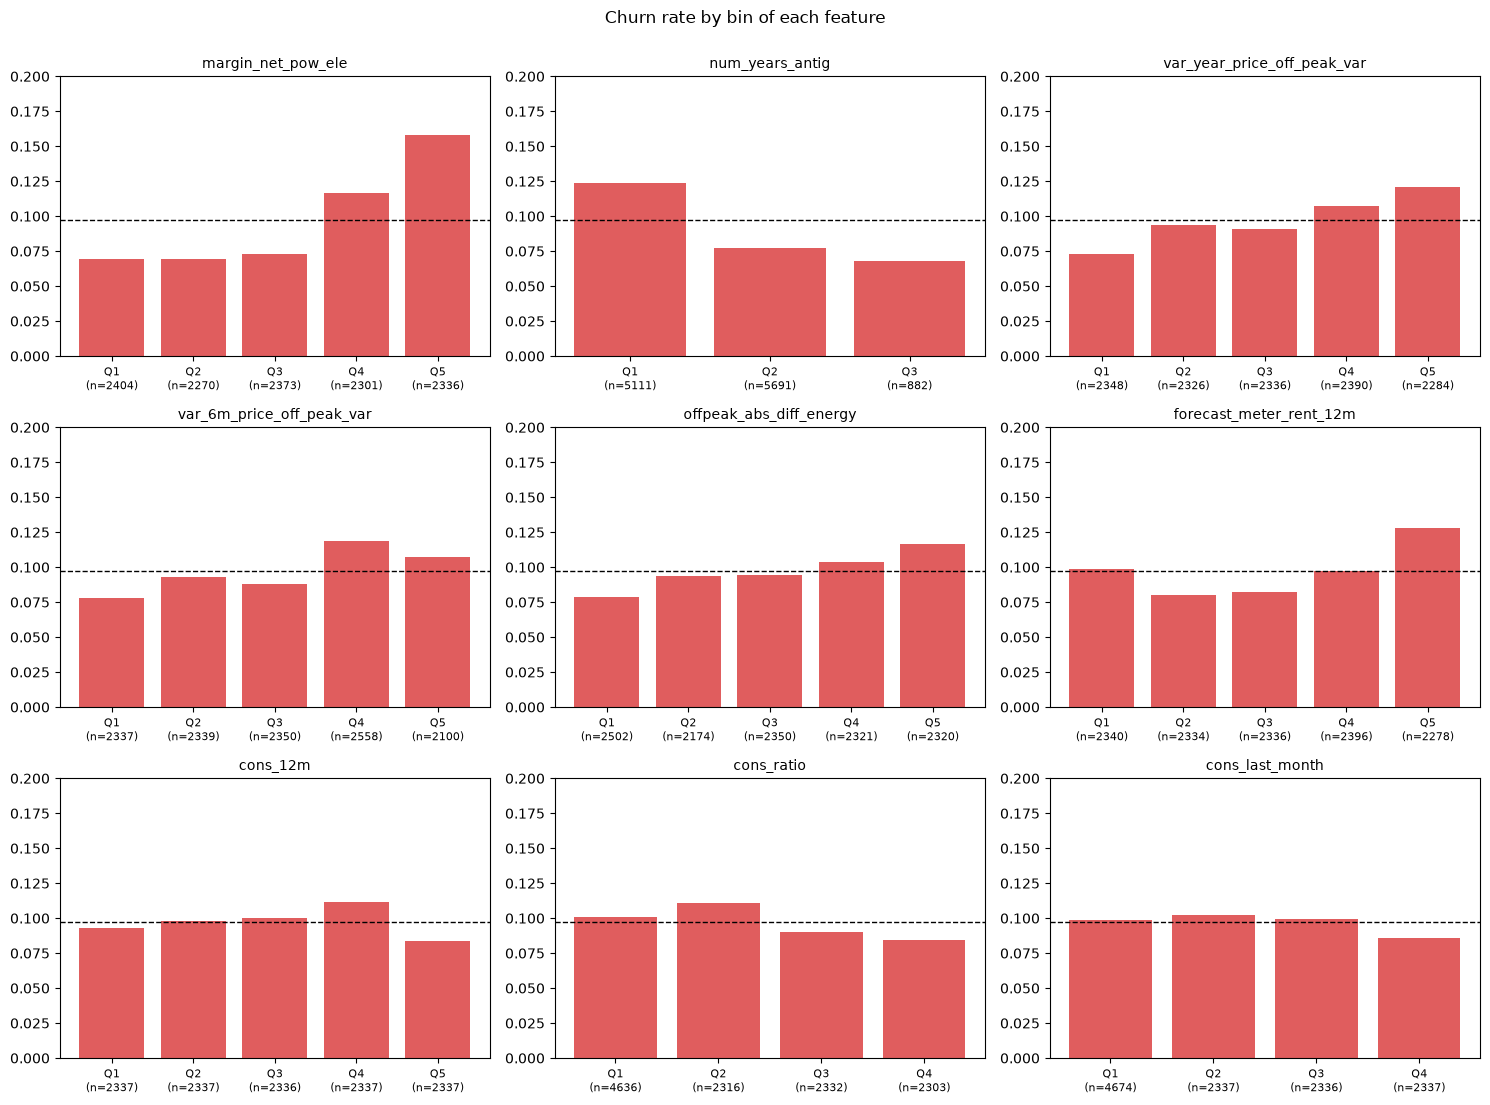

In [77]:
def quintile_plot(c, ax):
    s = train[c]
    groups = pd.qcut(s, 5, duplicates="drop")
    rate = y_train.groupby(groups, observed=True).mean()
    n = y_train.groupby(groups, observed=True).size()
    ax.bar(range(len(rate)), rate.values, color="tab:red", alpha=0.75)
    ax.axhline(y_train.mean(), color="black", ls="--", lw=1)
    ax.set_xticks(range(len(rate))); ax.set_xticklabels([f"Q{i+1}\n(n={k})" for i, k in enumerate(n)], fontsize=8)
    ax.set_title(c, fontsize=10); ax.set_ylim(0, 0.2)

to_plot = profile["feature"].head(6).tolist() + ["cons_12m", "cons_ratio", "cons_last_month"]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), to_plot):
    quintile_plot(c, ax)
fig.suptitle("Churn rate by bin of each feature", y=1.00)
plt.tight_layout(); plt.show()

- Newer clients and higher-margin clients churn more (newest tenure group ≈ 12.4% vs ≈ 6.8% for the longest; top margin fifth ≈ 15.8% vs ≈ 6.9% for the bottom).


### 7.5 Categorical features
Churn rate per category (with counts) and a chi-square test of "churn is independent of this category". With ~11,700 rows, even small differences produce tiny p-values, so judge importance by the size of the gap (`vs_overall`), not by p alone. Categories with fewer than 100 clients are unreliable.

In [78]:
from scipy.stats import chi2_contingency

for c in ["channel_sales", "origin_up"]:
    tab = train.groupby(c)["churn"].agg(n="count", churn_rate="mean")
    tab["vs_overall"] = tab["churn_rate"] / y_train.mean()
    tab["too_small"] = tab["n"] < 100
    p = chi2_contingency(pd.crosstab(train[c], y_train))[1]
    print(f"\n{c}  (chi-square p = {p:.2e})")
    display(tab.sort_values("n", ascending=False).round(3))


channel_sales  (chi-square p = 3.63e-16)


,n,churn_rate,vs_overall,too_small
channel_sales,,,,
foosdfpfkusacimwkcsosbicdxkicaua,5400,0.122,1.252,False
MISSING,2975,0.079,0.810,False
lmkebamcaaclubfxadlmueccxoimlema,1485,0.053,0.548,False
usilxuppasemubllopkaafesmlibmsdf,1101,0.103,1.057,False
ewpakwlliwisiwduibdlfmalxowmwpci,710,0.073,0.754,False
sddiedcslfslkckwlfkdpoeeailfpeds,9,0.000,0.000,True
epumfxlbckeskwekxbiuasklxalciiuu,3,0.000,0.000,True
fixdbufsefwooaasfcxdxadsiekoceaa,1,0.000,0.000,True



origin_up  (chi-square p = 1.51e-23)


,n,churn_rate,vs_overall,too_small
origin_up,,,,
lxidpiddsbxsbosboudacockeimpuepw,5689,0.126,1.296,False
kamkkxfxxuwbdslkwifmmcsiusiuosws,3414,0.060,0.618,False
ldkssxwpmemidmecebumciepifcamkci,2526,0.083,0.856,False
MISSING,53,0.075,0.777,True
usapbepcfoloekilkwsdiboslwaxobdp,2,0.000,0.000,True


- Both categorical features show a large, statistically clear spread in churn (chi-square p ≈ 4e-16 for `channel_sales`, ≈ 2e-23 for `origin_up`), and the size of the gap matters more than the p-value at this sample size.
- `channel_sales`: the largest channel (n = 5,400) churns at 12.2% (1.25× the 9.7% overall rate) while the channel with n = 1,485 churns at only 5.3% (0.55×). The "MISSING" channel (n = 2,975) sits below average at 7.9%, so missing here behaves like a real group, not noise.
- `origin_up`: the largest origin (n = 5,689) churns at 12.6% (1.30×), versus 6.0% (0.62×) for the origin with n = 3,414.
- The remaining categories (9, 3 and 1 clients in `channel_sales`; 53 and 2 in `origin_up`) show 0% or odd rates, but they are too small to trust.
- Action: keep both as features. One-hot encode them in the pipeline with `min_frequency=100`, so the tiny categories are pooled into an "infrequent" bucket. The MISSING channel keeps its own column, since it is large enough.

---
## 8. Preprocessing pipeline

### Framework
Preprocessing must **learn its settings from the training data only** (medians, scaling, category lists) and then apply those same settings to any new data. A `Pipeline` + `ColumnTransformer` guarantees this.

| Feature group | Treatment | Why |
|---|---|---|
| Skewed numeric (|skew| > 1) | median impute + missing flag, then **Yeo-Johnson** + standardize | Yeo-Johnson straightens skew like a log, but also handles zeros and negative values (e.g. price differences) |
| `forecast_price_pow_off_peak` | treat `0` as missing, then impute + flag, then standardize | 0 is not a real price; the 94 zeros distorted its skew |
| `has_gas` | pass through (already 0/1) | |
| `channel_sales`, `origin_up` | one-hot; categories with < 100 clients pooled into an "infrequent" bucket | Replaces `group_rare`, but learned on training data only, and unseen categories at prediction time no longer crash |

*Median because it is robust to the heavy tails. Missing flags because "missing" can itself carry signal*

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

#  model matrices: only the kept numeric features + the two raw categoricals
cat_cols    = ["channel_sales", "origin_up"]
binary_cols = ["has_gas"]
count_cols  = ["nb_prod_act_capped"]
zero_cols   = ["forecast_price_pow_off_peak"]      
model_cols  = features + cat_cols

X_train, y_train = train[model_cols], train["churn"]
X_test,  y_test  = test[model_cols],  test["churn"]

numeric_cols = [c for c in features if c not in binary_cols + count_cols + zero_cols]
skew_train   = X_train[numeric_cols].skew()              # columns that get Yeo-Johnson
skewed_cols  = skew_train[skew_train.abs() > 1].index.tolist()
regular_cols = [c for c in numeric_cols if c not in skewed_cols]

print("skewed  (", len(skewed_cols), "):", skewed_cols)
print("regular (", len(regular_cols), "):", regular_cols)

skewed  ( 17 ): ['cons_12m', 'cons_last_month', 'forecast_cons_year', 'forecast_discount_energy', 'forecast_meter_rent_12m', 'margin_net_pow_ele', 'net_margin', 'num_years_antig', 'pow_max', 'var_year_price_off_peak_var', 'var_year_price_off_peak_fix', 'var_6m_price_off_peak_var', 'var_6m_price_off_peak_fix', 'cons_ratio', 'offpeak_diff_energy', 'offpeak_diff_power', 'offpeak_abs_diff_energy']
regular ( 2 ): ['forecast_price_energy_off_peak', 'forecast_price_energy_peak']


In [81]:
def zero_to_nan(X):
    return X.replace(0, np.nan)

impute = lambda: SimpleImputer(strategy="median", add_indicator=True)  

preprocessor = ColumnTransformer(
    transformers=[
        ("skewed",   Pipeline([("impute", impute()), ("power", PowerTransformer(method="yeo-johnson"))]), skewed_cols),
        ("pow_zero", Pipeline([("zero_to_nan", FunctionTransformer(zero_to_nan, feature_names_out="one-to-one")),
                               ("impute", impute()), ("scale", StandardScaler())]), zero_cols),
        ("binary",   "passthrough", binary_cols),
        ("regular", "passthrough", regular_cols + count_cols), # didn't impute the regular columns-the task is to model using a random forest which ignores
        ("cat",      OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), cat_cols),
    ],
    remainder="drop",                      
).set_output(transform="pandas")

### 8.1 Fit on train, apply to test, and check the output

In [82]:
Xt = preprocessor.fit_transform(X_train)     # learns medians / scaling / categories from TRAIN only
Xs = preprocessor.transform(X_test)          # applies those same settings to TEST

print("train:", Xt.shape, "| test:", Xs.shape)
print("NaN after:", Xt.isna().sum().sum(), "/", Xs.isna().sum().sum(), "| inf:", np.isinf(Xt).sum().sum())
assert list(Xt.columns) == list(Xs.columns)

print("\nskew before -> after Yeo-Johnson (train):")
before = X_train[skewed_cols].skew()
after = Xt[[f"skewed__{c}" for c in skewed_cols]].skew()
after.index = after.index.str.replace("skewed__", "", regex=False)
cmp = pd.concat(
    [before.rename("before"), after.rename("after")],
    axis=1
).round(2)
display(cmp)

print("Output columns:", list(Xt.columns))

train: (11684, 37) | test: (2922, 37)
NaN after: 0 / 0 | inf: 0

skew before -> after Yeo-Johnson (train):


,before,after
cons_12m,6.03,0.06
cons_last_month,6.38,-0.06
forecast_cons_year,17.36,-0.08
forecast_discount_energy,5.18,5.07
forecast_meter_rent_12m,1.44,-0.05
margin_net_pow_ele,4.58,0.18
net_margin,37.74,0.03
num_years_antig,1.43,0.01
pow_max,6.01,-0.13
var_year_price_off_peak_var,12.03,4.89


Output columns: ['skewed__cons_12m', 'skewed__cons_last_month', 'skewed__forecast_cons_year', 'skewed__forecast_discount_energy', 'skewed__forecast_meter_rent_12m', 'skewed__margin_net_pow_ele', 'skewed__net_margin', 'skewed__num_years_antig', 'skewed__pow_max', 'skewed__var_year_price_off_peak_var', 'skewed__var_year_price_off_peak_fix', 'skewed__var_6m_price_off_peak_var', 'skewed__var_6m_price_off_peak_fix', 'skewed__cons_ratio', 'skewed__offpeak_diff_energy', 'skewed__offpeak_diff_power', 'skewed__offpeak_abs_diff_energy', 'skewed__missingindicator_cons_ratio', 'skewed__missingindicator_offpeak_diff_energy', 'skewed__missingindicator_offpeak_diff_power', 'skewed__missingindicator_offpeak_abs_diff_energy', 'pow_zero__forecast_price_pow_off_peak', 'pow_zero__missingindicator_forecast_price_pow_off_peak', 'binary__has_gas', 'regular__forecast_price_energy_off_peak', 'regular__forecast_price_energy_peak', 'regular__nb_prod_act_capped', 'cat__channel_sales_MISSING', 'cat__channel_sales_

In [83]:
print(Xt.columns.tolist()) # Xt columns have a new prefix ie; skewed

['skewed__cons_12m', 'skewed__cons_last_month', 'skewed__forecast_cons_year', 'skewed__forecast_discount_energy', 'skewed__forecast_meter_rent_12m', 'skewed__margin_net_pow_ele', 'skewed__net_margin', 'skewed__num_years_antig', 'skewed__pow_max', 'skewed__var_year_price_off_peak_var', 'skewed__var_year_price_off_peak_fix', 'skewed__var_6m_price_off_peak_var', 'skewed__var_6m_price_off_peak_fix', 'skewed__cons_ratio', 'skewed__offpeak_diff_energy', 'skewed__offpeak_diff_power', 'skewed__offpeak_abs_diff_energy', 'skewed__missingindicator_cons_ratio', 'skewed__missingindicator_offpeak_diff_energy', 'skewed__missingindicator_offpeak_diff_power', 'skewed__missingindicator_offpeak_abs_diff_energy', 'pow_zero__forecast_price_pow_off_peak', 'pow_zero__missingindicator_forecast_price_pow_off_peak', 'binary__has_gas', 'regular__forecast_price_energy_off_peak', 'regular__forecast_price_energy_peak', 'regular__nb_prod_act_capped', 'cat__channel_sales_MISSING', 'cat__channel_sales_ewpakwlliwisiwdu

- Yeo-Johnson cut skew sharply for most columns (e.g. net_margin 37.7 → 0.03), while a few zero-heavy columns remain skewed. Missing values were handled by the median imputer plus missing flags.